## Task 1: Calculating Precision and Recall from a Confusion Matrix

### Objective
Generate a balanced synthetic dataset, train a Logistic Regression classifier, inspect the confusion matrix, and manually compute Precision and Recall before validating with scikit-learn.

In [2]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score

# 1: Generate a balanced synthetic dataset (200 samples, 5 features)
X, y = make_classification(n_samples=200, n_features=5, random_state=42)

# 2: Initialize and train a basic Logistic Regression classifier
model = LogisticRegression()
model.fit(X, y)

# 3: Predict binary class labels using the default threshold of 0.5
y_pred = model.predict(X)

# 4: Extract and unpack the confusion matrix components
cm = confusion_matrix(y, y_pred)
tn, fp, fn, tp = cm.ravel()

# 5: Display confusion matrix counts and scikit-learn metric scores
print(f"Confusion Matrix:\n{cm}")
print(f"True Positives (TP): {tp}, False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}, True Negatives (TN): {tn}")
print("-" * 40)
print(f"Sklearn Precision: {precision_score(y, y_pred):.4f}")
print(f"Sklearn Recall:    {recall_score(y, y_pred):.4f}")

Confusion Matrix:
[[84 15]
 [13 88]]
True Positives (TP): 88, False Positives (FP): 15
False Negatives (FN): 13, True Negatives (TN): 84
----------------------------------------
Sklearn Precision: 0.8544
Sklearn Recall:    0.8713


### Task 1 Analysis & Questions

#### Manual Calculations:
- **Precision:**
  $$\text{Precision} = \frac{TP}{TP + FP} = \frac{88}{88 + 15} = \frac{88}{103} \approx 0.8544$$

- **Recall:**
  $$\text{Recall} = \frac{TP}{TP + FN} = \frac{88}{88 + 13} = \frac{88}{101} \approx 0.8713$$

Both manual calculations match the results obtained from `precision_score` (0.8544) and `recall_score` (0.8713) precisely.

---

#### Questions 
- **Q1: If you change the model's decision threshold from 0.5 to 0.8, will Precision go up or down? What about Recall?**
  - **Precision goes up:** Setting a higher threshold (0.8) makes the model more conservative, requiring 80% confidence before predicting positive. This substantially decreases False Positives ($FP$), which increases Precision.
  - **Recall goes down:** A stricter threshold causes ambiguous positive cases to be missed (turning into False Negatives, $FN$), which lowers the Recall.

- **Q2: In what real-world application is high Recall critical, and why?**
  - High Recall is critical in **medical diagnostics** (e.g., cancer detection) where missing a true positive case (a False Negative) has severe health consequences. In contrast, applications like **spam filtering** favor high Precision to prevent marking legitimate personal emails as spam.

## Task 2: Exploring the Impact of Class Imbalance

### Objective
Create an imbalanced classification problem (95% negative, 5% positive) and observe how overall Accuracy fails to reflect true model performance on the minority class.

In [4]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Step 1: Generate an imbalanced dataset (95% Class 0, 5% Class 1)
X_imb, y_imb = make_classification(
    n_samples=1000, 
    n_features=5, 
    weights=[0.95, 0.05], 
    random_state=42
)

# Step 2: Fit the Logistic Regression model on the imbalanced data
model_imb = LogisticRegression()
model_imb.fit(X_imb, y_imb)

# Step 3: Generate class predictions
y_pred_imb = model_imb.predict(X_imb)

# Step 4: Evaluate and compare Accuracy, Precision, and Recall
print("Imbalanced Evaluation Metrics:")
print(f"Accuracy:  {accuracy_score(y_imb, y_pred_imb):.4f}")
print(f"Precision: {precision_score(y_imb, y_pred_imb):.4f}")
print(f"Recall:    {recall_score(y_imb, y_pred_imb):.4f}")

Imbalanced Evaluation Metrics:
Accuracy:  0.9530
Precision: 0.7143
Recall:    0.2679


### Task 2: Exploring the Impact of Class Imbalance

#### Key Findings
- **High Accuracy is Deceptive:** Although the classifier shows an overall Accuracy of **95.30%**, this result is strongly biased by the majority class (Class 0, 95% of data).
- **Poor Minority Detection:** The **Recall is only 26.79%**, which reveals that the model misses more than **73%** of all actual positive cases (Class 1). Relying solely on accuracy completely masks this failure.

---

#### Questions to Think About

- **Q1: Why can a model achieve over 90% accuracy on an imbalanced dataset while still failing to detect the minority class?**
  - In a dataset where 95% of records belong to the negative class, a simple model that classifies all instances as negative without any learning still achieves 95% accuracy.
  - Overall accuracy is dominated by True Negatives ($TN$), so the metric remains high even if the model detects very few True Positives ($TP$).

- **Q2: Why is the Precision-Recall curve often preferred over the ROC curve when evaluating heavily imbalanced datasets?**
  - The ROC curve measures the False Positive Rate ($\text{FPR} = \frac{FP}{TN + FP}$). In highly imbalanced contexts, the massive count of $TN$ keeps the FPR tiny, creating an overly optimistic ROC curve.
  - In contrast, the Precision-Recall curve isolates the positive minority class ($TP$, $FP$, and $FN$) without relying on $TN$, directly exposing low recall and false alarms.

## Task 3: Plotting and Analyzing the Precision-Recall Curve

### Objective
Plot the Precision-Recall curve across varying decision thresholds and calculate Average Precision (AP) / Area Under the PR Curve (AUC-PR).

Average Precision (AP / AUC-PR): 0.5189


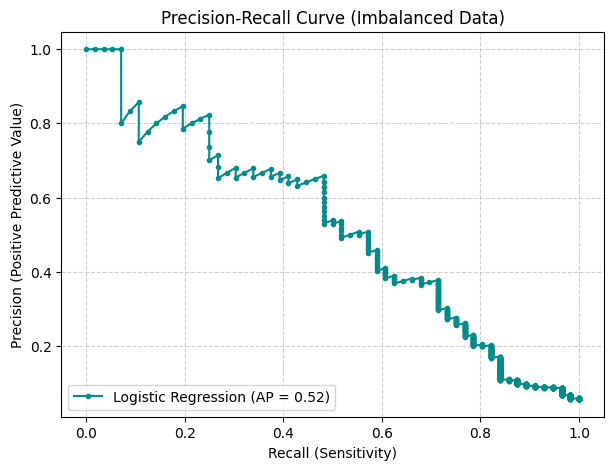

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# 1. Obtain predicted continuous probabilities for the positive class (Class 1)
y_scores = model_imb.predict_proba(X_imb)[:, 1]

# 2. Compute Precision and Recall across varying probability thresholds
precision, recall, thresholds = precision_recall_curve(y_imb, y_scores)

# 3. Calculate Average Precision (Area under the PR curve)
ap_score = average_precision_score(y_imb, y_scores)
print(f"Average Precision (AP / AUC-PR): {ap_score:.4f}")

# 4. Plot the Precision-Recall Curve with the trade-off highlighted
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, marker='.', color='darkcyan', label=f'Logistic Regression (AP = {ap_score:.2f})')
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision (Positive Predictive Value)')
plt.title('Precision-Recall Curve (Imbalanced Data)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower left')
plt.show()

### Analysis & Questions

#### 1. Metric & Plot Summary
- **Average Precision (AP / AUC-PR):** **0.5189** (~0.52)
- **Baseline Comparison:** In a dataset with 5% positive instances, a random classifier would have an AP around 0.05. An AP of 0.52 indicates that the Logistic Regression model has meaningful discriminatory power above chance, despite the heavy class imbalance.

#### 2. Curve Behavior & Observations
- **Initial High Precision:** For low Recall values (< 0.20), Precision stays relatively high (between 0.80 and 1.00).
- **Steep Decline:** As Recall is pushed higher to capture more positive cases, Precision drops steadily.
- **Extreme Recall Drop:** When Recall approaches 1.0, Precision falls below 0.10, showing that catching every positive sample introduces many false alarms (False Positives).

---

#### 3. Questions to Think About

- **Q1: What shape does an ideal Precision-Recall curve have, and where is the optimal operational point on the curve?**
  - **Ideal Shape:** An ideal curve reaches the top-right corner $(1.0, 1.0)$, forming a full rectangle with an Area Under the Curve (AUC-PR) equal to 1.0. This means maintaining 100% Precision while detecting 100% of positives (Recall = 1.0).
  - **Optimal Point:** The optimal operating point lies around the "elbow" of the curve—roughly where Recall is between 0.40 and 0.50 and Precision is around 0.65. This region typically yields the highest balanced $F_1\text{-score}$. The exact threshold depends on the business objective (whether missing positives or false alarms is more costly).

- **Q2: What happens to Precision when Recall approaches 1.0, and why does this inverse trade-off occur?**
  - **What happens:** As Recall approaches 1.0, Precision drops sharply toward the dataset's positive class proportion (~5%).
  - **Why it happens:** To capture every single true positive ($FN \to 0$), the classification threshold must be set very low, causing the model to label almost all data points as positive. This floods the predictions with False Positives ($FP$), blowing up the denominator in $\text{Precision} = \frac{TP}{TP + FP}$ and pulling Precision down.